In [1]:
import hopsy
import numpy as np
import numpy.typing as npt
from typing import Callable
import arviz as az
from scipy.stats import dirichlet
import pandas as pd

In [2]:
from pathlib import Path

FOLDER = "W2_idata"
ordner = Path(FOLDER)
ordner.mkdir(parents=True, exist_ok=True)

In [3]:
class Problem:
    def __init__(self, A, b, model):
        self.A = np.asarray(A, dtype=np.float64)
        self.b = np.asarray(b, dtype=np.float64).ravel()
        self.model = model


In [4]:
import warnings

import numpy as np

import cpp_rattle_2 as cpp_rattle


class CustomProposal:
    """RATTLE proposal on {q : S sigma(q) = c}, algebraic squashing.

        sigma(q) = c0 + r q/sqrt(q^2+1),  d = r/(q^2+1)^{3/2},  dlog d/dq = -3q/(1+q^2)

        h1(q) = -log pi(x(q)) - sum_i log d_i(q) + 1/2 log det(J M^-1 J^T),  J = S diag(d)

    Die beiden Klammerterme sind einzeln abschaltbar, aber nur fuer Diagnoselaeufe;
    beide gehoeren in den Hamiltonian.
    """

    def __init__(
        self,
        problem,
        starting_point,
        fisher,
        map_guess,
        param_matr,
        proj_matr,
        beta,
        equality_constraints,
        box_constraints,
        particular_solution=None,
        momentum=None,
        stepsize=1.0,
        integration_length=1,
        nuts=False,
        random_int_length=False,
        pullback_momentum=False,
        include_gram_term=True,
        include_squash_logdet=True,
        reversibility_check=True,
        reversibility_tol=1e-5,
        constraint_tol=1e-8,
        n_inner_step=1,
        adaptive_inner_steps=False,
        squash_eps=1e-12,
        feasibility_tol=0.0,
        seed=None,
    ):
        self.problem = problem
        self.stepsize = stepsize
        self.integration_length = integration_length
        self.random_int_length = random_int_length
        self.nuts = nuts
        if nuts:
            warnings.warn("nuts=True is stored but not implemented.", RuntimeWarning)

        S, c = equality_constraints
        self.S = np.asarray(S, dtype=np.float64)
        self.c = np.asarray(c, dtype=np.float64)

        lower, upper = box_constraints
        self.lower = np.asarray(lower, dtype=np.float64)
        self.upper = np.asarray(upper, dtype=np.float64)

        self.param_matr = np.asarray(param_matr, dtype=np.float64)
        self.proj_matr = np.asarray(proj_matr, dtype=np.float64)
        self.beta = beta
        self.particular_solution = (
            np.zeros(self.S.shape[1], dtype=np.float64)
            if particular_solution is None
            else np.asarray(particular_solution, dtype=np.float64)
        )

        self.squash_eps = float(squash_eps)
        self.feasibility_tol = float(feasibility_tol)
        self.include_gram_term = bool(include_gram_term)
        self.include_squash_logdet = bool(include_squash_logdet)
        self.reversibility_check = bool(reversibility_check)
        # gegen das Residuenhistogramm kalibrieren, nicht raten
        self.reversibility_tol = float(reversibility_tol)
        self.constraint_tol = float(constraint_tol)
        self.n_inner_step = int(n_inner_step)
        self.adaptive_inner_steps = bool(adaptive_inner_steps)

        self.n_proposals = 0
        self.n_squash_clips = 0
        self.n_integrator_failures = 0
        self.n_constraint_failures = 0
        self.n_reversibility_failures = 0
        self.n_nonfinite_energy = 0
        self.last_integrator_error = None
        self.last_reversibility_residual = np.nan
        self.max_reversibility_residual = 0.0
        self.last_constraint_residual = np.nan
        self.max_constraint_residual = 0.0

        self.map_guess = np.asarray(map_guess, dtype=np.float64)
        self.map_guess_full = self.affine_transformation(self.map_guess)

        self.base_metric = np.asarray(fisher, dtype=np.float64)
        self.base_metric_sqrt = np.linalg.cholesky(self.base_metric)
        self.pullback_momentum = pullback_momentum
        if pullback_momentum:
            warnings.warn(
                "pullback_momentum=True is inconsistent with the constant metric "
                "in h2; stationarity is lost.",
                RuntimeWarning,
            )

        self.metric = self.pullback_metric()
        self.metric_inv = np.linalg.inv(self.metric)
        self.metric_sqrt = np.linalg.cholesky(self.metric)

        self.rng = np.random.default_rng(seed)

        self.state_transformed = None
        self.state = np.asarray(starting_point, dtype=np.float64)

        self.proposal = self._state.copy()
        self.proposal_q = self.state_transformed.copy()
        self.momentum = momentum
        self.proposal_mom = momentum
        self._proposal_valid = False

    # ------------------------------------------------------------------ state

    @property
    def state(self):
        return self._state

    @state.setter
    def state(self, value):
        self._state = np.asarray(value, dtype=np.float64)
        self.state_transformed = self.squash_inv(
            self.affine_transformation(self._state)
        )

    # ------------------------------------------------------------------- maps

    def affine_transformation(self, x):
        return self.param_matr @ x + self.particular_solution

    def projection(self, x):
        return self.proj_matr @ (x - self.particular_solution)

    def squash(self, q):
        q = np.asarray(q, dtype=np.float64)
        return (
            0.5 * (self.upper + self.lower)
            + 0.5 * (self.upper - self.lower) * (q / np.sqrt(q**2 + 1.0))
        )

    def squash_inv(self, x):
        x = np.asarray(x, dtype=np.float64)
        hh = (2.0 * x - (self.upper + self.lower)) / (self.upper - self.lower)
        hh_clipped = np.clip(hh, -1.0 + self.squash_eps, 1.0 - self.squash_eps)
        if np.any(hh_clipped != hh):
            self.n_squash_clips += 1
        return hh_clipped / np.sqrt(1.0 - hh_clipped**2)

    def squash_jacobian_diag(self, q):
        q = np.asarray(q, dtype=np.float64)
        return 0.5 * (self.upper - self.lower) / ((q**2 + 1.0) ** 1.5)

    def squash_jacobian(self, q):
        return np.diag(self.squash_jacobian_diag(q))

    # ----------------------------------------------------------------- metric

    def pullback_metric(self):
        q_map = self.squash_inv(self.map_guess_full)
        d = self.squash_jacobian_diag(q_map)
        m_reg = (
            self.proj_matr.T @ self.base_metric @ self.proj_matr
            + self.beta * np.eye(self.param_matr.shape[0])
        )
        return d[:, None] * m_reg * d[None, :]

    def jacob_constr(self, q):
        d = self.squash_jacobian_diag(q)
        return self.S * d[None, :]

    def project_onto_cotangent_space(self, q, mom):
        J = self.jacob_constr(q)
        G = J @ self.metric_inv @ J.T
        lam = np.linalg.solve(G, J @ (self.metric_inv @ mom))
        return mom - J.T @ lam

    def constraint_residual(self, q):
        return float(np.linalg.norm(self.S @ self.squash(q) - self.c, ord=np.inf))

    # --------------------------------------------------------------- momentum

    def _resolve_rng(self, rng):
        if rng is not None and hasattr(rng, "standard_normal"):
            return rng
        return self.rng

    def sample_momentum(self, q, rng=None):
        rng = self._resolve_rng(rng)
        if self.pullback_momentum:
            try:
                with np.errstate(over="raise", invalid="raise"):
                    mom_red = self.base_metric_sqrt @ rng.standard_normal(
                        self.base_metric_sqrt.shape[0]
                    )
                    mom = self.squash_jacobian(q).T @ self.proj_matr.T @ mom_red
                    return self.project_onto_cotangent_space(q, mom)
            except (FloatingPointError, np.linalg.LinAlgError):
                pass
        mom = self.metric_sqrt @ rng.standard_normal(self.metric_sqrt.shape[0])
        return self.project_onto_cotangent_space(q, mom)

    # ------------------------------------------------------------- Hamiltonian

    def logdet_squash_jacobian(self, q):
        return float(np.sum(np.log(self.squash_jacobian_diag(q))))

    def log_gram_term(self, q):
        """0.5 * log det(J M^-1 J^T). Reweight old draws with exp(-this)."""
        J = self.jacob_constr(q)
        sign, logdet = np.linalg.slogdet(J @ self.metric_inv @ J.T)
        if sign <= 0.0 or not np.isfinite(logdet):
            return np.inf
        return 0.5 * logdet

    def h1(self, q):
        theta = self.squash(q)
        x = self.projection(theta)
        log_pi = self.problem.model.log_density(x)
        if not np.isfinite(log_pi):
            return np.inf
        value = -log_pi
        if self.include_squash_logdet:
            value = value - self.logdet_squash_jacobian(q)
        if self.include_gram_term:
            value = value + self.log_gram_term(q)
        return value

    def dh2_dmom(self, mom):
        return self.metric_inv @ mom

    def h2(self, mom):
        return 0.5 * mom @ self.dh2_dmom(mom)

    def h(self, q, mom):
        return self.h1(q) + self.h2(mom)

    # ------------------------------------------------------------- integration

    def _integrate(self, q, mom, n_steps):
        try:
            q_out, mom_out = cpp_rattle.integrate(
                self.problem.model,
                q,
                mom,
                self.metric_inv,
                self.S,
                self.c,
                self.lower,
                self.upper,
                self.proj_matr,
                self.stepsize,
                n_steps,
                self.particular_solution,
                self.include_gram_term,
                self.n_inner_step,
                self.adaptive_inner_steps,
                self.include_squash_logdet,
            )
        except Exception as exc:
            self.last_integrator_error = f"{type(exc).__name__}: {exc}"
            return None
        q_out = np.asarray(q_out, dtype=np.float64)
        mom_out = np.asarray(mom_out, dtype=np.float64)
        if not (np.all(np.isfinite(q_out)) and np.all(np.isfinite(mom_out))):
            self.last_integrator_error = "non-finite integrator output"
            return None
        return q_out, mom_out

    def _check_reversibility(self, q0, mom0, q1, mom1, n_steps):
        back = self._integrate(q1, -mom1, n_steps)
        if back is None:
            self.last_reversibility_residual = np.inf
            return False
        q_back, mom_back = back
        scale_q = max(1.0, float(np.linalg.norm(q0)))
        scale_p = max(1.0, float(np.linalg.norm(mom0)))
        residual = max(
            float(np.linalg.norm(q_back - q0)) / scale_q,
            float(np.linalg.norm(mom_back + mom0)) / scale_p,
        )
        self.last_reversibility_residual = residual
        self.max_reversibility_residual = max(self.max_reversibility_residual, residual)
        return residual <= self.reversibility_tol

    # --------------------------------------------------------------- proposal

    def _invalidate(self):
        self._proposal_valid = False
        self.proposal_q = self.state_transformed.copy()
        self.proposal_mom = None if self.momentum is None else self.momentum.copy()
        self.proposal = self._state.copy()
        return self.proposal

    def propose(self, rng=None):
        rng = self._resolve_rng(rng)
        self.n_proposals += 1
        self._proposal_valid = False

        self.momentum = self.sample_momentum(self.state_transformed, rng)

        if self.random_int_length:
            n_steps = int(rng.integers(1, self.integration_length + 1))
        else:
            n_steps = int(self.integration_length)

        forward = self._integrate(self.state_transformed, self.momentum, n_steps)
        if forward is None:
            self.n_integrator_failures += 1
            return self._invalidate()
        proposal_q, proposal_mom = forward

        residual = self.constraint_residual(proposal_q)
        self.last_constraint_residual = residual
        self.max_constraint_residual = max(self.max_constraint_residual, residual)
        if not (residual <= self.constraint_tol):
            self.n_constraint_failures += 1
            return self._invalidate()

        if self.reversibility_check and not self._check_reversibility(
            self.state_transformed, self.momentum, proposal_q, proposal_mom, n_steps
        ):
            self.n_reversibility_failures += 1
            return self._invalidate()

        self.proposal_q = proposal_q
        self.proposal_mom = proposal_mom
        self.proposal = self.projection(self.squash(proposal_q))
        self._proposal_valid = True
        return self.proposal

    def log_acceptance_probability(self):
        if not self._proposal_valid:
            return -np.inf

        theta = self.affine_transformation(self.proposal)
        if (self.problem.A @ theta - self.problem.b > self.feasibility_tol).any():
            return -np.inf

        h_proposal = self.h(self.proposal_q, self.proposal_mom)
        if not np.isfinite(h_proposal):
            return -np.inf

        h_state = self.h(self.state_transformed, self.momentum)
        if not np.isfinite(h_state):
            self.n_nonfinite_energy += 1
            return 0.0

        return -(h_proposal - h_state)

    def accept_proposal(self):
        self._state = self.proposal.copy()
        self.state_transformed = self.proposal_q.copy()
        return self._state

    # ------------------------------------------------------------ diagnostics

    def diagnostics(self):
        n = max(1, self.n_proposals)
        return {
            "n_proposals": self.n_proposals,
            "squash_clips": self.n_squash_clips,
            "integrator_failures": self.n_integrator_failures,
            "constraint_failures": self.n_constraint_failures,
            "reversibility_failures": self.n_reversibility_failures,
            "reversibility_failure_rate": self.n_reversibility_failures / n,
            "max_reversibility_residual": self.max_reversibility_residual,
            "max_constraint_residual": self.max_constraint_residual,
            "nonfinite_energy": self.n_nonfinite_energy,
            "last_integrator_error": self.last_integrator_error,
        }

In [5]:
from tqdm.auto import trange


def _da_init(eps0, target):
    """Dual-Averaging-Zustand (Hoffman & Gelman)."""
    return dict(mu=np.log(10.0 * eps0), log_eps_bar=0.0, h_bar=0.0, m=0,
                target=target, gamma=0.05, t0=10.0, kappa=0.75)


def _da_update(st, alpha):
    """Ein Adaptionsschritt; gibt die neue Schrittweite zurueck."""
    st["m"] += 1
    m = st["m"]
    eta = 1.0 / (m + st["t0"])
    st["h_bar"] = (1.0 - eta) * st["h_bar"] + eta * (st["target"] - alpha)

    log_eps = st["mu"] - np.sqrt(m) / st["gamma"] * st["h_bar"]
    w = m ** (-st["kappa"])
    st["log_eps_bar"] = w * log_eps + (1.0 - w) * st["log_eps_bar"]

    return float(np.exp(log_eps))


def run_chain(prop, n_draws, n_warmup=0, seed=0, target_accept=0.8,
              adapt=True, desc=None, progress=True):
    """Metropolis-Hastings mit optionaler Schrittweiten-Adaption im Warmup.

    Gibt nur die Draws nach dem Warmup zurueck.
    """
    rng = np.random.default_rng(seed)
    x = np.empty((n_draws, prop.state.size))
    accepted = np.zeros(n_draws, dtype=bool)
    invalid = np.zeros(n_draws, dtype=bool)

    da = _da_init(prop.stepsize, target_accept) if (adapt and n_warmup) else None

    it = trange(n_warmup + n_draws, desc=desc, disable=not progress, leave=False)
    for i in it:
        warm = i < n_warmup

        prop.propose(rng)
        lap = prop.log_acceptance_probability()

        acc = np.log(rng.random()) < lap
        if acc:
            prop.accept_proposal()

        if warm:
            if da is not None:
                alpha = float(np.exp(min(lap, 0.0)))
                if not np.isfinite(alpha):
                    alpha = 0.0
                prop.stepsize = _da_update(da, alpha)
                if i == n_warmup - 1:                      # einfrieren
                    prop.stepsize = float(np.exp(da["log_eps_bar"]))
        else:
            j = i - n_warmup
            x[j] = prop.state
            accepted[j] = acc
            invalid[j] = not prop._proposal_valid

        if progress and i % 200 == 0:
            if warm:
                it.set_postfix(phase="warmup", eps=f"{prop.stepsize:.3g}")
            else:
                j = i - n_warmup + 1
                it.set_postfix(phase="sample", eps=f"{prop.stepsize:.3g}",
                               acc=f"{accepted[:j].mean():.2f}",
                               inv=f"{invalid[:j].mean():.3f}")

    return x, accepted, invalid


def run_chains(make_prop, n_chains=1, n_draws=4000, n_warmup=1000, seed0=0,
               target_accept=0.8, adapt=True, verbose=True, progress=True):
    xs, accs, invs, props = [], [], [], []

    for ch in range(n_chains):
        p = make_prop(ch)
        x, acc, inv = run_chain(p, n_draws, n_warmup=n_warmup, seed=seed0 + ch,
                                target_accept=target_accept, adapt=adapt,
                                desc=f"chain {ch}", progress=progress)
        xs.append(x)
        accs.append(acc)
        invs.append(inv)
        props.append(p)
        if verbose:
            print(f"chain {ch}: acc={acc.mean():.3f}  invalid={inv.mean():.4f}  "
                  f"stepsize={p.stepsize:.4g}")

    return np.stack(xs), np.stack(accs), np.stack(invs), props

In [6]:
def make_affine(A):
    def f(x):
        c = np.zeros_like(x)
        c = np.concatenate([c, np.array([1])])
        return A@x + c
    return f

class Dirichlet:
    #def __init__(self, upper_bounds: np.ndarray = np.ones(2), parameters: np.ndarray = np.ones(3)):
    def __init__(self, upper_bounds_red: np.ndarray, parameters: np.ndarray):
        self.upper_bounds_red = np.array(upper_bounds_red)
        self.parameters = np.array(parameters)
        self.n = len(list(upper_bounds_red))
        if (len(list(parameters)) != self.n + 1):
            raise ValueError("Dimensions of parameters and bounds don't match!")


    def log_density(self, x):
        weights = (self.parameters-1)*np.log(x)
        term1 = np.sum(weights)
        term2 = -np.sum(np.log(self.upper_bounds_red))
        return term1 + term2


    def log_gradient(self, x):
        weights = (self.parameters-1)
        return weights/x

class Dirichlet_red:
    def __init__(self, affine_jacobian: np.ndarray, upper_bounds: np.ndarray, parameters: np.ndarray):
        self.distribution = Dirichlet(upper_bounds_red = upper_bounds, parameters=parameters)
        self.affine = make_affine(affine_jacobian)
        self.affine_jacobian = affine_jacobian

    def log_density(self, x):
        y = self.affine(x)
        return self.distribution.log_density(y)

    def log_gradient(self, x):
        y = self.affine(x)
        return self.affine_jacobian.T@self.distribution.log_gradient(y)

In [7]:
# Function for calculating the fisher matrix of Dirichlet based on Parameters
def fisher_dirichlet_map(alpha):
    """
    Fisher matrix (negative Hessian of log-density)
    at the MAP of a 3D Dirichlet distribution
    restricted to the 2D simplex.

    Parameters
    ----------
    alpha : iterable of length 3
        Dirichlet parameters (all must be > 1)

    Returns
    -------
    numpy.ndarray
        2x2 Fisher matrix at the MAP.
    """
    alpha = np.asarray(alpha, dtype=float)

    if alpha.shape != (3,):
        raise ValueError("alpha must have length 3")

    if np.any(alpha <= 1):
        raise ValueError("all alpha_i must be > 1 for an interior MAP")

    beta = alpha - 1
    S = beta.sum()

    return S**2 * np.array([
        [1/beta[0] + 1/beta[2], 1/beta[2]],
        [1/beta[2], 1/beta[1] + 1/beta[2]]
    ])

def dirichlet_covariance_n_dim(alpha):
    """
    Kovarianzmatrix einer Dirichletverteilung auf dem n-dimensionalen Simplex,
    dargestellt durch die ersten n Koordinaten.

    Parameters
    ----------
    alpha : array-like, shape (n+1,)
        Dirichlet-Parameter alpha_1, ..., alpha_{n+1}.

    Returns
    -------
    cov : ndarray, shape (n, n)
        Kovarianzmatrix der ersten n Komponenten.
    """
    alpha = np.asarray(alpha, dtype=float)

    if alpha.ndim != 1:
        raise ValueError("alpha muss ein eindimensionales Array sein.")
    if len(alpha) < 2:
        raise ValueError("alpha muss mindestens zwei Parameter enthalten.")
    if np.any(alpha <= 0):
        raise ValueError("Alle Dirichlet-Parameter muessen positiv sein.")

    alpha0 = np.sum(alpha)
    a = alpha[:-1]  # n explizite Koordinaten

    cov = -np.outer(a, a)
    np.fill_diagonal(cov, a * (alpha0 - a))

    cov /= alpha0**2 * (alpha0 + 1)

    return cov

In [8]:
def param_matr_calc(n):
    last_row = -1*np.ones(n).reshape(1,n)
    return np.concatenate((np.eye(n), last_row), axis=0)

def proj_matr_calc(n):
    last_col = np.zeros(n).reshape(n,1)
    return np.concatenate((np.eye(n), last_col), axis=1)

def A_matr_box(n):
    A = np.zeros((2*(n+1), (n+1)))
    count = 0
    for i in range(n+1):
        A[count, i] = 1
        A[count+1, i] = -1
        count += 2
    return A

def rhs_vector(n):
    b = np.zeros(2*(n+1))
    for i in range(2*(n+1)):
        if i%2==0:
            b[i]=1
    return b.reshape(2*(n+1),1)

def S_matr_calc(n):
    return np.ones(n+1).reshape(1,n+1)

def part_sol_calc(n):
    x_ = np.zeros(n+1)
    x_[-1] = 1
    return x_

In [9]:
def dirichlet_map(alpha):
    alpha = np.asarray(alpha, dtype=float)
    #print(alpha.shape)

    if alpha.ndim != 1:
        raise ValueError("alpha must be a 1D array")
    if np.any(alpha <= 1):
        raise ValueError("MAP is only strictly interior if all alpha_i > 1")

    return (alpha - 1) / (np.sum(alpha) - len(alpha))


def fisher_dirichlet_map(alpha):
    """
    Fisher-/curvature matrix of the negative log Dirichlet density
    with respect to unconstrained coordinates x_1,...,x_{K-1},
    where x_K = 1 - sum_{i=1}^{K-1} x_i.

    Evaluated at the interior MAP.
    """
    alpha = np.asarray(alpha, dtype=float)
    x = dirichlet_map(alpha)

    a = alpha - 1
    k = len(alpha)

    F = np.empty((k - 1, k - 1), dtype=float)

    # Hessian of -log p(x) on the simplex chart:
    # F_ij = delta_ij * (alpha_i - 1) / x_i^2
    #        + (alpha_K - 1) / x_K^2
    common = a[-1] / x[-1] ** 2

    for i in range(k - 1):
        for j in range(k - 1):
            F[i, j] = common
            if i == j:
                F[i, j] += a[i] / x[i] ** 2

    return F

In [10]:
def draw_triangle(ax, labels=("(0,0)", "(1,0)", "(0,1)")):
    corners = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0], [0.0, 0.0]])
    ax.plot(corners[:, 0], corners[:, 1], color="black", lw=1)
    offsets = [(-0.05, -0.05), (1.03, -0.05), (-0.05, 1.03)]
    for label, (x, y) in zip(labels, offsets):
        ax.text(x, y, label, ha="center", va="center", fontsize=9)
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.set_aspect("equal")
    ax.axis("off")


def plot_simplex(idata_1chain, idata_4chain, var_name="x", layout="side"):
    nrows, ncols = (1, 2) if layout == "side" else (2, 1)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 6 * nrows))

    panels = [(idata_1chain, "1 Chain", axes[0]), (idata_4chain, "4 Chains", axes[1])]
    chain_colors = plt.cm.tab10.colors

    for idata, title, ax in panels:
        draw_triangle(ax)
        arr = idata.posterior[var_name].values  # (chain, draw, 2) -- bereits (x, y)
        n_chains = arr.shape[0]
        for c in range(n_chains):
            pts = arr[c]
            label = f"Chain {c}" if n_chains > 1 else None
            ax.scatter(pts[:, 0], pts[:, 1], s=8, alpha=0.3,
                       color=chain_colors[c % len(chain_colors)],
                       label=label, edgecolors="none")
        if n_chains > 1:
            ax.legend(loc="upper right", frameon=False, fontsize=8)
        ax.set_title(f"{title}: '{var_name}'")

    fig.tight_layout()
    return fig, axes

def plot_simplices_3(idata_1chain, idata_4chain, idata_3, var_name="x",
                 layout="side", titles=("1 Chain", "4 Chains", "4 Chains (2)")):
    nrows, ncols = (1, 3) if layout == "side" else (3, 1)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    panels = list(zip((idata_1chain, idata_4chain, idata_3), titles, axes))
    chain_colors = plt.cm.tab10.colors
    for idata, title, ax in panels:
        draw_triangle(ax)
        arr = idata.posterior[var_name].values  # (chain, draw, 2) -- bereits (x, y)
        n_chains = arr.shape[0]
        for c in range(n_chains):
            pts = arr[c]
            label = f"Chain {c}" if n_chains > 1 else None
            ax.scatter(pts[:, 0], pts[:, 1], s=8, alpha=0.3,
                       color=chain_colors[c % len(chain_colors)],
                       label=label, edgecolors="none")
        if n_chains > 1:
            ax.legend(loc="upper right", frameon=False, fontsize=8)
        ax.set_title(f"{title}: '{var_name}'")
    fig.tight_layout()
    return fig, axes

In [17]:
# Definiere das Polytop der freien Parameter
dim = 2

upper_bounds_red = np.ones(dim)
lower_bounds_red = np.zeros_like(upper_bounds_red)
A = A_matr_box(dim)
b = rhs_vector(dim)

# Definiere verschiedene mögliche Dirichlet-Verteilungen
PARAMS = [ ([i]*1 + dim*[2]) for i in range(2, 4001)]
MAPS = [dirichlet_map(p) for p in PARAMS]
FISHERS = [fisher_dirichlet_map(p) for p in PARAMS]
COV_INVS = [np.linalg.inv(dirichlet_covariance_n_dim(p)) for p in PARAMS]
COVS = [dirichlet_covariance_n_dim((p)) for p in PARAMS]

# Definiere hochdimensionalen Dirichlet
idx = 6 #6
print(PARAMS[idx])
parameters = np.array(PARAMS[idx])
R = param_matr_calc(dim)
model = Dirichlet_red(affine_jacobian=R, upper_bounds=upper_bounds_red, parameters=parameters)

#problem = hopsy.Problem(A, b, model)
problem = Problem(A, b, model)

# Equality constraints bestimmen die Geometrie, nicht die Verteilung selbst
S = S_matr_calc(dim)
c = np.array([1])

# Parametermatrix in den vollen Raum
param_matr = param_matr_calc(dim)
proj_matr = proj_matr_calc(dim)

fisher_test = FISHERS[idx]
print(fisher_test.min())
print(MAPS[idx])
print((idx+2-1)/(idx+2+1), 1/(idx+3), 1/(idx+3))

[8, 2, 2]
81.0
[0.77777778 0.11111111 0.11111111]
0.7777777777777778 0.1111111111111111 0.1111111111111111


k: 8.0


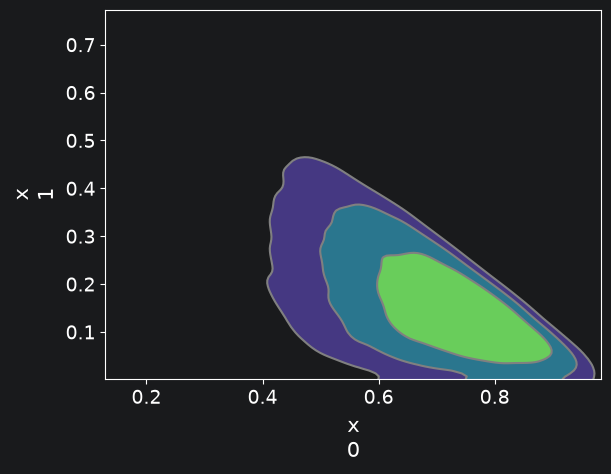

In [18]:
N_SAMPLES = 40000  # Größe des kleinen IID-Baseline-Samples
alpha = np.asarray(parameters, dtype=float)  # muss Länge 8 haben

k = alpha[0]
print("k:", k)

n_samples = 50000  # Größe des großen Ground-Truth-Samples

# Insgesamt n_samples + N_SAMPLES unabhängige Samples erzeugen
samples_all = dirichlet.rvs(
    alpha,
    size=n_samples + N_SAMPLES,
    random_state=42,
)

# Großes Ground-Truth-Sample
samples_analytical = samples_all[:n_samples, :dim]

# Kleines IID-Baseline-Sample
samples_ref = samples_all[n_samples:, :dim]

# InferenceData für das große Sample
idata_analytical = az.from_dict(
    posterior={
        "x": samples_analytical[None, :, :]
    }
)
idata_analytical.to_netcdf(f"{FOLDER}/iid_ground_truth_alpha={alpha}.nc")

# InferenceData für das kleine Sample
idata_ref = az.from_dict(
    posterior={
        "x": samples_ref[None, :, :]
    }
)
idata_ref.to_netcdf((f"{FOLDER}/iid_baseline_alpha={alpha}.nc"))

az.plot_pair(
    idata_analytical,
    var_names=["x"],
    kind="kde",
    #marginals=True,
)
plt.show()


In [19]:
# Prepare for Initialization
upper_bounds = np.ones(dim + 1)
lower_bounds = np.zeros_like(upper_bounds)
map_guess = MAPS[idx][:dim]  #np.array([1 / 3, 1 / 3])
print("map: ", map_guess)
fisher = COV_INVS[idx]
particular_solution = np.array([0, 0, 1])  #part_sol_calc(dim)
param_matr = param_matr
proj_matr = proj_matr
box_constraints = (lower_bounds, upper_bounds)
A = problem.A
b = problem.b
print(A)
S = S
c = c
#starting_point = (1/dim)*np.ones(dim)
eps = 0.001
chebyshev_center = np.squeeze(hopsy.compute_chebyshev_center(problem))
#starting_point = proj_matr@chebyshev_center
#starting_point = np.array([0.1, 0.1])
starting_point = map_guess.copy() #+ eps*np.ones(dim)
equality_constraints = (S, c)
beta = 1 * np.diag(fisher).max()
print("beta = ", beta)
stepsize = 1.5 #1.2
integration_length = 4  #100 #40 #10 #30 #15 #6

map:  [0.77777778 0.11111111]
[[ 1.  0.  0.]
 [-1.  0.  0.]
 [ 0.  1.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  1.]
 [ 0.  0. -1.]]
beta =  156.0


chain 0:   0%|          | 0/41000 [00:00<?, ?it/s]

chain 0: acc=0.820  invalid=0.0000  stepsize=1.053


chain 1:   0%|          | 0/41000 [00:00<?, ?it/s]

chain 1: acc=0.830  invalid=0.0000  stepsize=1.037


chain 2:   0%|          | 0/41000 [00:00<?, ?it/s]

chain 2: acc=0.842  invalid=0.0000  stepsize=1.012


chain 3:   0%|          | 0/41000 [00:00<?, ?it/s]

chain 3: acc=0.819  invalid=0.0000  stepsize=1.059
          mean        sd    hdi_3%   hdi_97%  mcse_mean   mcse_sd  \
x[0]  0.666500  0.130028  0.425385  0.901043   0.000257  0.000490   
x[1]  0.166877  0.103365  0.008141  0.355159   0.000277  0.000421   

           ess_bulk      ess_tail     r_hat  
x[0]  226893.809214  64437.451521  1.000121  
x[1]  100838.681943  43541.684405  1.000040  
{'n_proposals': 41000, 'squash_clips': 0, 'integrator_failures': 0, 'constraint_failures': 0, 'reversibility_failures': 0, 'reversibility_failure_rate': 0.0, 'max_reversibility_residual': 5.169544676216575e-06, 'max_constraint_residual': 9.998586403270338e-10, 'nonfinite_energy': 0, 'last_integrator_error': None}


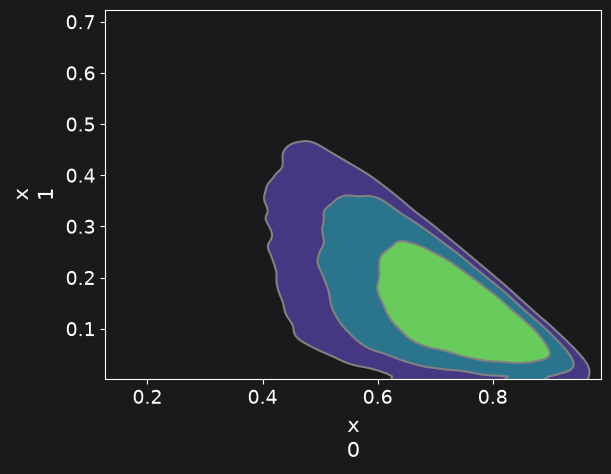

In [20]:
N_SAMPLES_HMC = N_SAMPLES

def make_prop(i):
    return CustomProposal(
        problem, starting_point, fisher, map_guess, param_matr, proj_matr, beta,
        equality_constraints, box_constraints,
        particular_solution=particular_solution,
        stepsize=stepsize, integration_length=integration_length,
    )

N_BURNIN = 1000   # ggf. hochsetzen, s.u.
N_CHAINS = 4

x, accepted, invalid, props = run_chains(make_prop, n_chains=N_CHAINS,
                                         n_draws=N_SAMPLES_HMC,
                                         n_warmup=N_BURNIN,
                                         target_accept=0.8)

idata_test = az.from_dict(
    posterior={"x": x},
    sample_stats={"diverging": invalid},
    dims={"x": ["param"]},
    #coords={"param": [str(p) for p in free_params]},
)


print(az.summary(idata_test, var_names=["x"], round_to="none"))
print(props[0].diagnostics())

az.plot_pair(idata_test, var_names=["x"], kind="kde")
plt.show()

[8. 2. 2.]


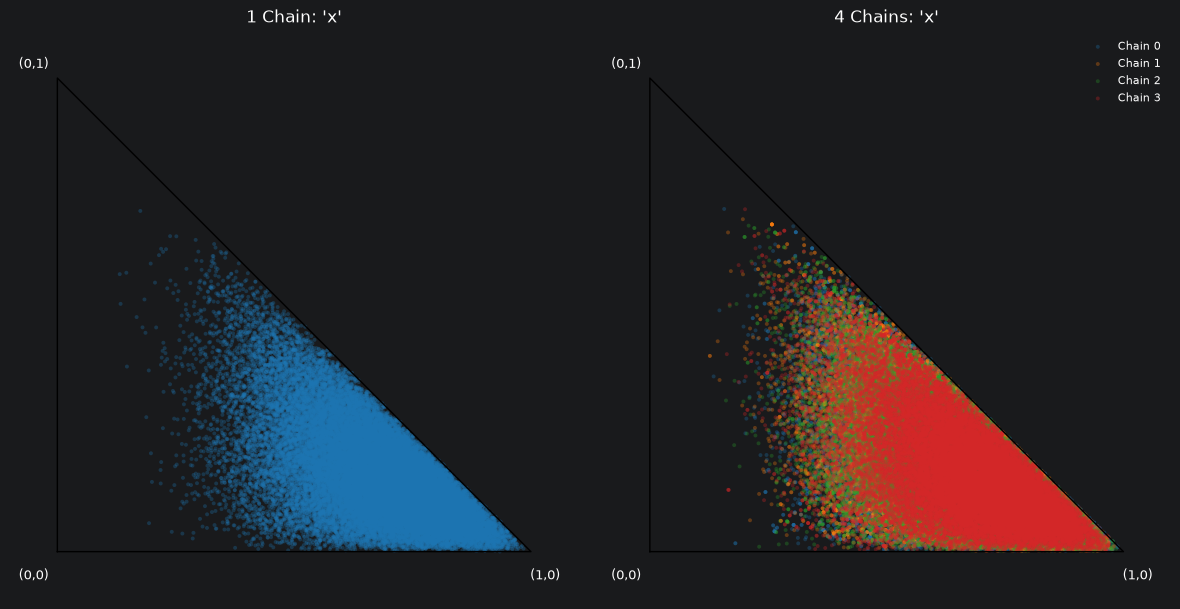

In [21]:
fig, axes = plot_simplex(idata_ref, idata_test, var_name="x")
print(alpha)
plt.show()

In [22]:
# Momente
def moments(idata, var_name="x"):
    arr = idata.posterior[var_name].values          # (chain, draw, 2)
    s = arr.reshape(-1, arr.shape[-1])              # (n_samples, 2)
    return s.mean(axis=0), np.cov(s, rowvar=False)


def _print_df(df):
    with pd.option_context("display.float_format", lambda v: f"{v:.5f}"):
        print(df)


def compare_moments_3chains(idata_a, idata_b, idata_c, var_name="x",
                    names=("ref", "hmc", "ghr")):
    ms, cs = zip(*(moments(i, var_name) for i in (idata_a, idata_b, idata_c)))
    m_a, m_b, m_c = ms
    c_a, c_b, c_c = cs

    means = pd.DataFrame(
        {names[0]: m_a, names[1]: m_b, names[2]: m_c,
         f"diff {names[1]}": m_b - m_a,
         f"diff {names[2]}": m_c - m_a},
        index=[f"{var_name}[{i}]" for i in range(len(m_a))],
    )

    idx = [f"var[{i}]" for i in range(len(m_a))] + ["cov[0,1]"]
    flat = lambda c: np.array(list(np.diag(c)) + [c[0, 1]])
    f_a, f_b, f_c = flat(c_a), flat(c_b), flat(c_c)
    covs = pd.DataFrame(
        {names[0]: f_a, names[1]: f_b, names[2]: f_c,
         f"diff {names[1]}": f_b - f_a,
         f"diff {names[2]}": f_c - f_a},
        index=idx,
    )

    corr = lambda c: c[0, 1] / np.sqrt(c[0, 0] * c[1, 1])

    print("Erstes Moment (Mittelwert):")
    _print_df(means.round(5)); print()
    print("Zweites Moment (Kovarianz):")
    _print_df(covs.round(5)); print()
    print("Korrelation: " + ", ".join(
        f"{n} = {corr(c):.5f}" for n, c in zip(names, (c_a, c_b, c_c))))
    return means, covs


def compare_moments(idata_a, idata_b, var_name="x", names=("ref", "hmc")):
    m_a, c_a = moments(idata_a, var_name)
    m_b, c_b = moments(idata_b, var_name)

    means = pd.DataFrame(
        {names[0]: m_a, names[1]: m_b, "diff": m_b - m_a},
        index=[f"{var_name}[{i}]" for i in range(len(m_a))],
    )

    idx = [f"var[{i}]" for i in range(len(m_a))] + ["cov[0,1]"]
    flat = lambda c: list(np.diag(c)) + [c[0, 1]]
    covs = pd.DataFrame(
        {names[0]: flat(c_a), names[1]: flat(c_b),
         "diff": np.array(flat(c_b)) - np.array(flat(c_a))},
        index=idx,
    )

    print("Erstes Moment (Mittelwert):")
    _print_df(means.round(5)); print()
    print("Zweites Moment (Kovarianz):")
    _print_df(covs.round(5)); print()
    print(f"Korrelation: {names[0]} = {c_a[0,1]/np.sqrt(c_a[0,0]*c_a[1,1]):.5f}, "
          f"{names[1]} = {c_b[0,1]/np.sqrt(c_b[0,0]*c_b[1,1]):.5f}")
    return means, covs


means, covs = compare_moments(idata_ref, idata_test, var_name="x")

Erstes Moment (Mittelwert):
         ref     hmc     diff
x[0] 0.66666 0.66650 -0.00016
x[1] 0.16661 0.16688  0.00027

Zweites Moment (Kovarianz):
              ref      hmc     diff
var[0]    0.01715  0.01691 -0.00024
var[1]    0.01069  0.01068 -0.00001
cov[0,1] -0.00857 -0.00849  0.00008

Korrelation: ref = -0.63309, hmc = -0.63175


In [17]:
idata_test.to_netcdf(f"{FOLDER}/idata_hmc_3_alpha={alpha}.nc")

'W2_idata/idata_hmc_3_alpha=[2000.    2.    2.].nc'